# Breast Cancer Classification Using Random Forest


<a id="toc" name="toc"></a>

## Table of Contents

- [1. Introduction](#section-1)
- [2. Algorithm Explanation](#section-2)
- [3. Exploratory Data Analysis (EDA)](#section-3)
    - [3.1 Import Libraries and Load the Data](#section-3-1)
    - [3.2 Dataset Structure](#section-3-2)
    - [3.3 Missing Values](#section-3-3)
    - [3.4 Target Variable](#section-3-4)
    - [3.5 Feature Distribution](#section-3-5)
    - [3.6 Features by Diagnosis](#section-3-6)
    - [3.7 Correlation Heatmap](#section-3-7)
    - [3.8 Relationship Between Two Features](#section-3-8)
    - [3.9 Features and Target Variable](#section-3-9)
    - [3.10 EDA Summary](#section-3-10)
- [4. Data Preprocessing](#section-4)
    - [4.1 Handling Missing Values](#section-4-1)
    - [4.2 Encoding the Target Variable](#section-4-2)
    - [4.3 Features and Target](#section-4-3)
    - [4.4 Check Duplicates and Outliers](#section-4-4)
    - [4.5 Train/Test Split](#section-4-5)
    - [4.6 Feature Scaling](#section-4-6)
- [5. Model Training](#section-5)
    - [5.1 Cross Validation Setup](#section-5-1)
    - [5.2 Baseline Random Forest](#section-5-2)
- [6. Handling Class Imbalance (Improving the Model)](#section-6)
- [7. Hyperparameter Tuning (Bonus)](#section-7)
    - [7.1 Grid Search](#section-7-1)
    - [7.2 Threshold Tuning](#section-7-2)
- [8. Model Evaluation](#section-8)
    - [8.1 Test Set Scores](#section-8-1)
    - [8.2 Before vs After (Baseline vs Tuned)](#section-8-2)
    - [8.3 Confusion Matrix](#section-8-3)
    - [8.4 Classification Report](#section-8-4)
    - [8.5 Cross Validation vs Test Set](#section-8-5)
    - [8.6 Feature Importance](#section-8-6)
- [9. Model Comparison (Bonus)](#section-9)
- [10. Conclusion](#section-10)

<a id="section-1" name="section-1"></a>

## 1. Introduction

This project aims to classify breast tumors as benign or malignant using the Random Forest Classifier.

We use the Breast Cancer Wisconsin Diagnostic Dataset, which contains 569 samples and 30 numerical features describing characteristics of cell nuclei.

The goal is to train and evaluate a machine learning model that can predict the tumor diagnosis based on these features.

**Dataset:** [Breast Cancer Wisconsin (Diagnostic) Data Set](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data) from Kaggle (`data/Breast_Cancer_Data.csv`). The features are computed from digitized images of a fine needle aspirate (FNA) of a breast mass.

**Prediction task:** predict the `diagnosis` of a tumor (**M = Malignant**, **B = Benign**) based on features such as:
- radius, perimeter and area of the cell nucleus (size)
- texture and smoothness
- concavity and concave points (shape)

Each feature is given as a **mean**, a **standard error (se)** and a **worst** (largest) value.

<a id="section-2" name="section-2"></a>

## 2. Algorithm Explanation

### What is Random Forest?
Random Forest is a supervised machine learning algorithm used for classification and regression. It combines multiple Decision Trees to make more reliable predictions.

### How Does Random Forest Work?
1. Random samples are selected from the training dataset.
2. Multiple Decision Trees are trained using these samples and random subsets of features.
3. Each tree predicts a class for the input.
4. The final classification is determined by majority voting among the trees.

### When Should We Use Random Forest?
Random Forest is useful for classification problems with multiple features and complex relationships. In this project, we use it to classify breast tumors as benign or malignant.

### Advantages
- Often provides good prediction accuracy.
- Reduces overfitting compared to a single Decision Tree.
- Handles multiple numerical features effectively.
- Does not usually require feature scaling.

### Limitations
- More computationally expensive than a single Decision Tree.
- Harder to interpret because it uses many trees.
- Performance depends on the data and model settings.

<a id="section-3" name="section-3"></a>

## 3. Exploratory Data Analysis (EDA)

Explore the structure of the dataset, check for missing values, identify the features and the target, and visualize the most important relationships.

<a id="section-3-1" name="section-3-1"></a>

### 3.1 Import Libraries and Load the Data

Import all the libraries used in the notebook and set one pink color theme for all the plots.

In [1]:
# Import the libraries we need
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)


# Light pink = benign, dark pink = malignant
PINKS = ['#C2185B', '#F06292', '#F8BBD0', '#880E4F']
DIAG_COLORS = {'B': '#F8A5C2', 'M': '#C2185B'}   # light pink = benign, dark pink = malignant
PINK_CMAP = LinearSegmentedColormap.from_list('pinks', ['#FFF0F5', '#F48FB1', '#880E4F'])
sns.set_theme(style='whitegrid', palette=PINKS)

Load the dataset from `data/Breast_Cancer_Data.csv` and display the first 5 rows.

In [2]:
df = pd.read_csv("data/Breast_Cancer_Data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


<a id="section-3-2" name="section-3-2"></a>

### 3.2 Dataset Structure

Check the number of rows and columns, the data type of each column and the basic statistics.

In [3]:
df.shape

(569, 33)

`df.info()` shows the type of each column and how many non-null values it has.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

`df.describe()` shows the mean, standard deviation, min, max and quartiles of every numerical column.

In [5]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


**Observation:**

1- The dataset has 569 rows and 33 columns: `id`, `diagnosis`, 30 numerical features and an empty column `Unnamed: 32`.

2- The features have very different ranges. For example, `area_mean` goes up to 2501, while `smoothness_mean` is below 0.17.

<a id="section-3-3" name="section-3-3"></a>

### 3.3 Missing Values

Count the missing values in every column.

In [6]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

**Observation:**

The dataset contains 569 missing values, all in the `Unnamed: 32` column. All other columns have no missing values.

<a id="section-3-4" name="section-3-4"></a>

### 3.4 Target Variable

Count how many tumors are benign (B) and malignant (M).

In [7]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

The dataset contains 357 benign cases (62.7%) and 212 malignant cases (37.3%). Benign cases are more common, indicating a moderate class imbalance.

Plot a **count plot** of the diagnosis to see the class balance visually.

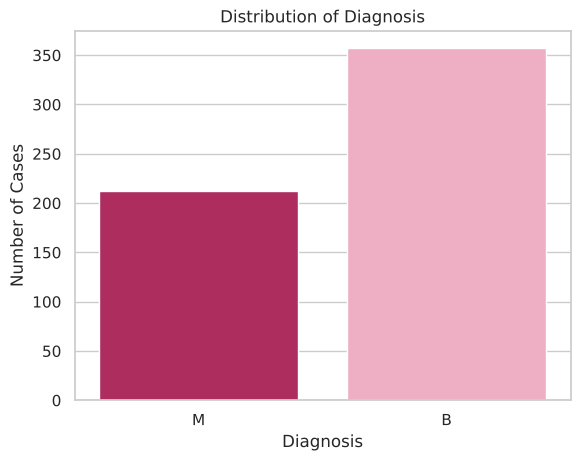

In [8]:
sns.countplot(data=df, x='diagnosis', hue='diagnosis', palette=DIAG_COLORS, legend=False)
plt.title('Distribution of Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Number of Cases')
plt.show()

<a id="section-3-5" name="section-3-5"></a>

### 3.5 Feature Distribution

Plot a **histogram** of `radius_mean` to see how the size of the cell nucleus is distributed.

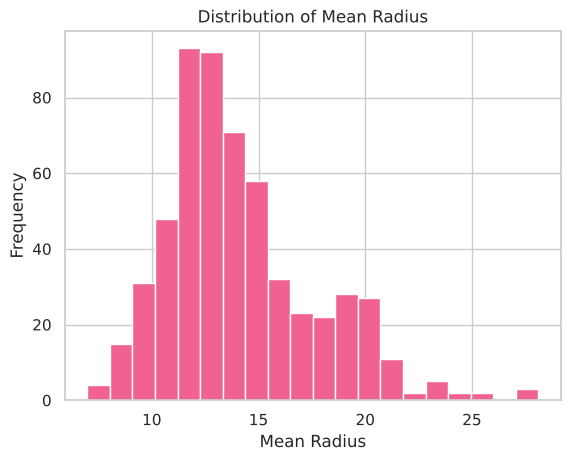

In [9]:
plt.hist(df['radius_mean'], bins=20, color=PINKS[1], edgecolor='white')

plt.title('Distribution of Mean Radius')
plt.xlabel('Mean Radius')
plt.ylabel('Frequency')

plt.show()

**Insight:**

Most mean radius values are concentrated between 11 and 15. The distribution is right-skewed, with a few samples showing larger values.

<a id="section-3-6" name="section-3-6"></a>

### 3.6 Features by Diagnosis

Use a **box plot** to compare `radius_mean` between benign and malignant tumors.

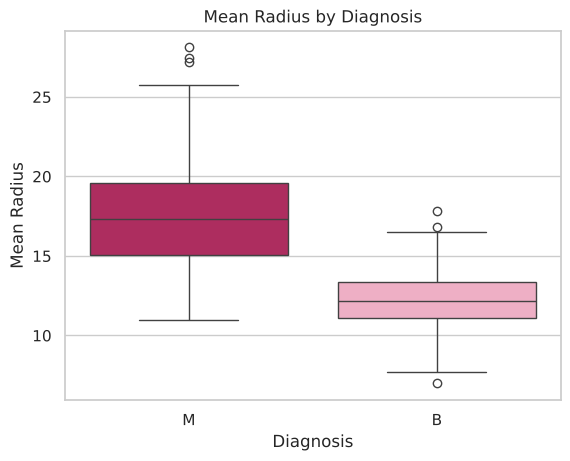

In [10]:
sns.boxplot(data=df, x='diagnosis', y='radius_mean', hue='diagnosis', palette=DIAG_COLORS, legend=False)

plt.title('Mean Radius by Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Mean Radius')

plt.show()

**Insight:**

Malignant tumors generally have higher mean radius values than benign tumors. This suggests that cell nucleus radius may be an important feature for distinguishing between the two classes.

Plot a **bar plot** of the average value of some features for each diagnosis.

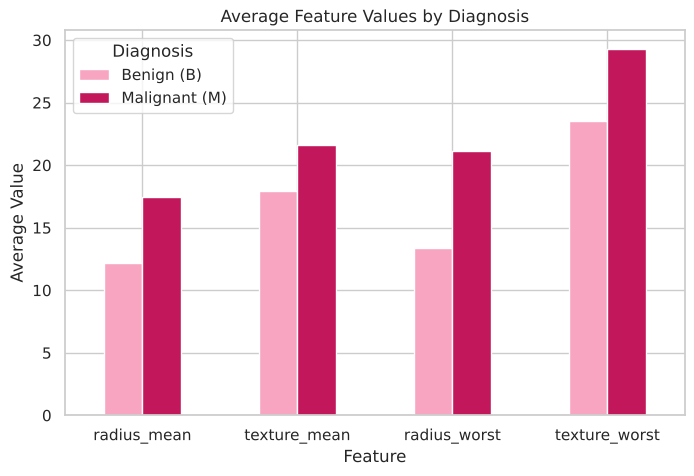

diagnosis,B,M
radius_mean,12.15,17.46
texture_mean,17.91,21.60
radius_worst,13.38,21.13
texture_worst,23.52,29.32


In [11]:
# Average of size and shape features for each diagnosis
avg = df.groupby('diagnosis')[['radius_mean', 'texture_mean', 'radius_worst', 'texture_worst']].mean().T
avg = avg[['B', 'M']]

avg.plot(kind='bar', color=[DIAG_COLORS['B'], DIAG_COLORS['M']], figsize=(8, 5))
plt.title('Average Feature Values by Diagnosis')
plt.xlabel('Feature')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(title='Diagnosis', labels=['Benign (B)', 'Malignant (M)'])
plt.show()

avg.round(2)

**Insight:**

1- Malignant tumors have a higher average for all 4 features.

2- The biggest difference is in `radius_worst` (13.4 for benign vs 21.1 for malignant), which shows that the largest cells in malignant tumors are much bigger.

3- Texture is also higher in malignant tumors, but the difference is smaller than for radius.

<a id="section-3-7" name="section-3-7"></a>

### 3.7 Correlation Heatmap

Plot a **correlation heatmap** of 5 mean features to see which features are related to each other.

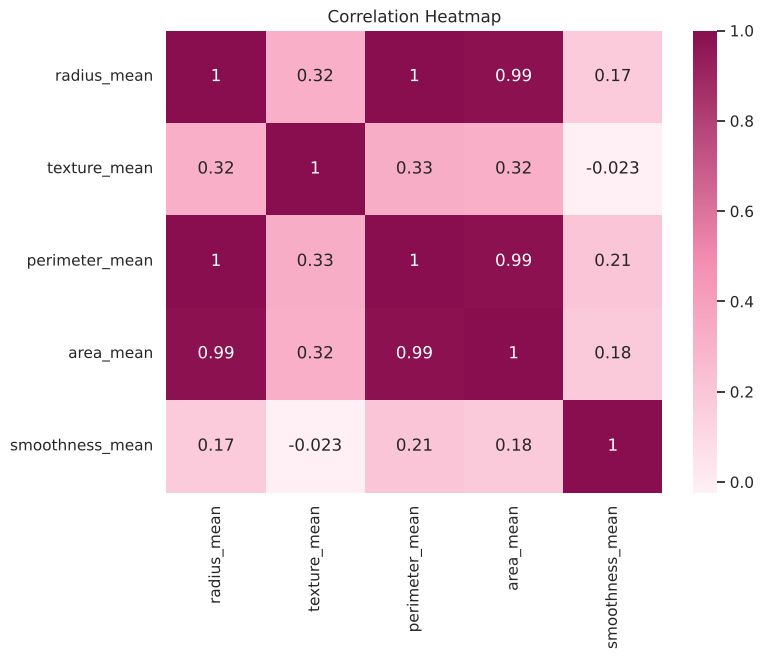

In [12]:
features = [
    'radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean',
    'smoothness_mean'
]

plt.figure(figsize=(8, 6))

sns.heatmap(df[features].corr(), annot=True, cmap=PINK_CMAP)

plt.title('Correlation Heatmap')
plt.show()

**Insight:**

The heatmap shows strong positive correlations between mean radius, mean perimeter, and mean area (approximately 0.99–1.00). This means that radius, perimeter and area are strongly correlated with each other, so these features contain closely related information about cell nucleus size.

<a id="section-3-8" name="section-3-8"></a>

### 3.8 Relationship Between Two Features

**Scatter plot** of `radius_mean` vs `texture_mean`, colored by diagnosis.

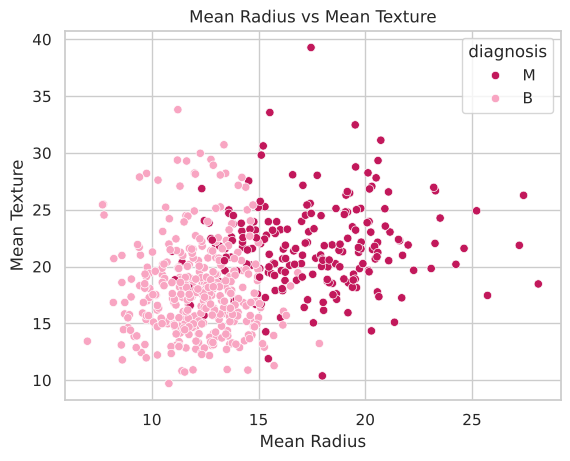

In [13]:
sns.scatterplot(
    data=df,
    x='radius_mean',
    y='texture_mean',
    hue='diagnosis',
    palette=DIAG_COLORS
)

plt.title('Mean Radius vs Mean Texture')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.show()

**Insight:**

Malignant cases generally have higher mean radius values than benign cases. However, there is some overlap between the two classes, suggesting that multiple features may be needed for accurate classification.

<a id="section-3-9" name="section-3-9"></a>

### 3.9 Features and Target Variable

**Features:** 30 numerical features describing cell nucleus characteristics.

**Target:** `diagnosis` (M = Malignant, B = Benign).

The `id` column is an identifier, and `Unnamed: 32` is an empty column.

<a id="section-3-10" name="section-3-10"></a>

### 3.10 EDA Summary

1- The dataset has 569 tumors and 30 numerical features, with no missing values except the empty column `Unnamed: 32`.

2- The classes are moderately imbalanced (63% benign and 37% malignant), so accuracy alone is not enough.

3- Malignant tumors are generally **bigger** (higher radius, perimeter and area), so size features look important for the prediction.

4- Radius, perimeter and area are almost perfectly correlated, so they carry similar information.

5- There is some overlap between the two classes, so the model needs to use many features together, which suits random forest.

<a id="section-4" name="section-4"></a>

## 4. Data Preprocessing

Prepare the dataset for the model: handle missing values, encode the target, check duplicates and outliers, split the data and decide whether scaling is needed.

<a id="section-4-1" name="section-4-1"></a>

### 4.1 Handling Missing Values

Remove the empty column `Unnamed: 32`, then check the new shape.

In [14]:
df = df.drop(columns=['Unnamed: 32'])
# The `Unnamed: 32` column was removed because it contained only missing values and provided no useful information for the model.

In [15]:
df.shape

(569, 32)

Remove the `id` column as well, then check the shape again.

In [16]:
df = df.drop(columns=['id'])
# The id column was removed because it is only an identifier and does not provide useful information for predicting the diagnosis.

In [17]:
df.shape

(569, 31)

<a id="section-4-2" name="section-4-2"></a>

### 4.2 Encoding the Target Variable

`diagnosis` is text (M / B), but the model needs numbers. Check the values before encoding, then convert them.

In [18]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

Encode **M (malignant) = 1** and **B (benign) = 0**, because malignant is the class we want to detect.

In [19]:
# Encoding: M (malignant) = 1, B (benign) = 0
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
df['diagnosis'].value_counts()

diagnosis
0    357
1    212
Name: count, dtype: int64

<a id="section-4-3" name="section-4-3"></a>

### 4.3 Features and Target

Separate the 30 input features (`X`) from the target (`y`).

In [20]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


**Features and Target:**

The dataset was divided into 30 numerical input features (X) and one target variable (y), which represents the diagnosis.

<a id="section-4-4" name="section-4-4"></a>

### 4.4 Check Duplicates and Outliers

Check whether there are duplicate rows or impossible negative values.

In [21]:
# Check duplicates and negative values
print("Duplicate rows:", df.duplicated().sum())
print("Negative values:", (X < 0).sum().sum())

Duplicate rows: 0
Negative values: 0


No duplicate rows and no negative values, so the data is clean.

Use the **IQR method** to find outliers in `area_mean` and check their diagnosis.

In [22]:
# Find outliers in area_mean using IQR
q1 = df['area_mean'].quantile(0.25)
q3 = df['area_mean'].quantile(0.75)
iqr = q3 - q1
outliers = df[(df['area_mean'] < q1 - 1.5 * iqr) | (df['area_mean'] > q3 + 1.5 * iqr)]
print("Number of outliers:", len(outliers))
print(outliers['diagnosis'].value_counts())

Number of outliers: 25
diagnosis
1    25
Name: count, dtype: int64


1- `area_mean` has 25 outliers, and all of them are malignant (1).

2- The outliers are real cancer cases, not mistakes, so we keep them.

3- Random forest is not affected much by outliers because it splits on values.

<a id="section-4-5" name="section-4-5"></a>

### 4.5 Train/Test Split

Split the data into 80% training and 20% testing, using `stratify=y` to keep the same class ratio in both sets.

In [23]:
# Split data 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (455, 30)
Test: (114, 30)


Check that the class ratio is the same in the training and test sets.

In [24]:
# Check the class ratio in train and test
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

diagnosis
0    0.626374
1    0.373626
Name: proportion, dtype: float64
diagnosis
0    0.631579
1    0.368421
Name: proportion, dtype: float64


Using `stratify=y` keeps the same ratio in the training and test sets (63% benign, 37% malignant).

The test set will not be used until model evaluation.

<a id="section-4-6" name="section-4-6"></a>

### 4.6 Feature Scaling

Check whether random forest needs scaling by comparing its predictions on scaled and unscaled data.

In [25]:
# Train on scaled and unscaled data and compare the predictions
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
pred1 = cross_val_predict(RandomForestClassifier(random_state=42), X_train, y_train, cv=5)
pred2 = cross_val_predict(RandomForestClassifier(random_state=42), X_train_scaled, y_train, cv=5)
print("Same predictions:", (pred1 == pred2).all())

Same predictions: True


The predictions are the same with and without scaling, because random forest splits on values (like radius_mean > 15) and scaling doesn't change the order of the values. So scaling is not needed.

<a id="section-5" name="section-5"></a>

## 5. Model Training

Use 5-fold cross validation on the training set to evaluate the models.

Focus on recall, because missing a cancer case is worse than a false alarm.

<a id="section-5-1" name="section-5-1"></a>

### 5.1 Cross Validation Setup

Create a 5-fold stratified cross validation to use for all models.

In [26]:
# 5-fold cross validation with shuffle
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

This function trains a model with cross validation and prints accuracy, precision, recall, F1 and the confusion matrix.

In [27]:
# Function to print the scores of a model using cross validation
def evaluate(model):
    y_pred = cross_val_predict(model, X_train, y_train, cv=cv)
    print("Accuracy:", round(accuracy_score(y_train, y_pred), 3))
    print("Precision:", round(precision_score(y_train, y_pred), 3))
    print("Recall:", round(recall_score(y_train, y_pred), 3))
    print("F1:", round(f1_score(y_train, y_pred), 3))
    print("Confusion matrix:\n", confusion_matrix(y_train, y_pred))

<a id="section-5-2" name="section-5-2"></a>

### 5.2 Baseline Random Forest

Train a basic random forest with the default settings. `oob_score=True` gives an extra accuracy check using the samples each tree did not see.

In [28]:
# Train the basic random forest model
rf_baseline = RandomForestClassifier(random_state=42, oob_score=True)
rf_baseline.fit(X_train, y_train)
print("OOB score:", round(rf_baseline.oob_score_, 3))

OOB score: 0.96


Evaluate the baseline model with cross validation.

In [29]:
# Scores of the basic model
evaluate(rf_baseline)

Accuracy: 0.965
Precision: 0.964
Recall: 0.941
F1: 0.952
Confusion matrix:
 [[279   6]
 [ 10 160]]


1- Accuracy is 96.5% and the OOB score is 96%, so they agree.

2- Recall is 0.941, which is lower than precision (0.964).

3- The confusion matrix (bottom-left number) shows that the model missed 10 cancers out of 170. The goal is to make this number smaller.

<a id="section-6" name="section-6"></a>

## 6. Handling Class Imbalance (Improving the Model)

The data is imbalanced: 63% benign and 37% malignant.

This is why accuracy alone is misleading: a model that always predicts benign gets 63% accuracy without finding any cancer.

Try `class_weight='balanced'`, which gives more weight to the malignant class.

Train a random forest with `class_weight='balanced'` and evaluate it.

In [30]:
# Random forest with balanced class weight
rf_balanced = RandomForestClassifier(class_weight='balanced', random_state=42)
evaluate(rf_balanced)

Accuracy: 0.965
Precision: 0.958
Recall: 0.947
F1: 0.953
Confusion matrix:
 [[278   7]
 [  9 161]]


Balanced class weight increased recall (0.941 → 0.947), and missed cancers went down from 10 to 9.

<a id="section-7" name="section-7"></a>

## 7. Hyperparameter Tuning (Bonus)

<a id="section-7-1" name="section-7-1"></a>

### 7.1 Grid Search

Use grid search to try different settings and pick the one with the best recall:

* n_estimators: number of trees
* max_depth: how deep each tree can go
* min_samples_leaf: minimum number of patients in each leaf
* class_weight: none or balanced

Grid search tries all 16 combinations with 5-fold cross validation and picks the one with the best recall.

In [31]:
# Grid search to find the best parameters (best recall)
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [None, 6],
    'min_samples_leaf': [1, 3],
    'class_weight': [None, 'balanced']
}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=cv, scoring='recall')
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)

Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}


Take the best model and evaluate it with cross validation.

In [32]:
# Scores of the tuned model
rf_best = grid.best_estimator_
evaluate(rf_best)

Accuracy: 0.963
Precision: 0.942
Recall: 0.959
F1: 0.95
Confusion matrix:
 [[275  10]
 [  7 163]]


1- The best parameters are: class_weight='balanced', min_samples_leaf=3, 100 trees and no max depth.

2- Recall went up from 0.941 to 0.959, and missed cancers went down from 10 to 7.

3- Precision went down a little (0.964 → 0.942) because there are more false alarms, but in cancer diagnosis missing a cancer is worse, so this model is better.

<a id="section-7-2" name="section-7-2"></a>

### 7.2 Threshold Tuning

The model predicts malignant when the probability is 0.5 or more. Try a threshold of 0.3 to see if it catches more cancers.

In [33]:
# Predictions with threshold = 0.3
y_prob = cross_val_predict(rf_best, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
y_pred_03 = (y_prob >= 0.3).astype(int)
print("Recall:", round(recall_score(y_train, y_pred_03), 3))
print("Precision:", round(precision_score(y_train, y_pred_03), 3))
print("Confusion matrix:\n", confusion_matrix(y_train, y_pred_03))

Recall: 0.965
Precision: 0.872
Confusion matrix:
 [[261  24]
 [  6 164]]


With 0.3, the model missed 6 cancers instead of 7, but false alarms went up from 10 to 24. That's too many false alarms for only 1 more cancer, so the threshold stays at 0.5.

**For model evaluation:** use `rf_best`, `X_test` and `y_test`.

<a id="section-8" name="section-8"></a>

## 8. Model Evaluation

The test set is used here for the first time. It has 114 patients (42 malignant, 72 benign) that the model never saw during training or tuning.

Evaluate the final model `rf_best` (from section 7) using accuracy, precision, recall, F1 score and the confusion matrix.

<a id="section-8-1" name="section-8-1"></a>

### 8.1 Test Set Scores

Predict the test set with `rf_best` and compute accuracy, precision, recall and F1.

In [34]:
# Predict on the test set with the final model
y_pred_test = rf_best.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_test), 3))
print("Precision:", round(precision_score(y_test, y_pred_test), 3))
print("Recall:", round(recall_score(y_test, y_pred_test), 3))
print("F1:", round(f1_score(y_test, y_pred_test), 3))

Accuracy: 0.974
Precision: 1.0
Recall: 0.929
F1: 0.963


1- Accuracy on the test set is 97.4%, so the model classified 111 out of 114 patients correctly.

2- Precision is 1.0, which means every time the model predicted malignant, it was really malignant (no false alarms).

3- Recall is 0.929, so the model found 39 out of 42 cancers and missed 3.

4- F1 is 0.963, which shows a good balance between precision and recall.

<a id="section-8-2" name="section-8-2"></a>

### 8.2 Before vs After (Baseline vs Tuned)

Compare the basic model `rf_baseline` with the final model `rf_best` on the test set, to see if handling class imbalance and tuning helped on new data.

In [35]:
# Test set scores of the basic model and the tuned model
y_pred_base = rf_baseline.predict(X_test)

before_after = pd.DataFrame({
    'Baseline (before)': [accuracy_score(y_test, y_pred_base), precision_score(y_test, y_pred_base),
                          recall_score(y_test, y_pred_base), f1_score(y_test, y_pred_base),
                          confusion_matrix(y_test, y_pred_base)[1, 0], confusion_matrix(y_test, y_pred_base)[0, 1]],
    'Tuned (after)': [accuracy_score(y_test, y_pred_test), precision_score(y_test, y_pred_test),
                      recall_score(y_test, y_pred_test), f1_score(y_test, y_pred_test),
                      confusion_matrix(y_test, y_pred_test)[1, 0], confusion_matrix(y_test, y_pred_test)[0, 1]]
}, index=['Accuracy', 'Precision', 'Recall', 'F1', 'Missed Cancers (FN)', 'False Alarms (FP)']).round(3)

# Show the counts as whole numbers
before_after = before_after.astype(object)
before_after.loc[['Missed Cancers (FN)', 'False Alarms (FP)']] = before_after.loc[['Missed Cancers (FN)', 'False Alarms (FP)']].astype(int)
before_after

,Baseline (before),Tuned (after)
Accuracy,0.974,0.974
Precision,1.0,1.0
Recall,0.929,0.929
F1,0.963,0.963
Missed Cancers (FN),3,3
False Alarms (FP),0,0


1- On the test set, the baseline and the tuned model got **exactly the same results**: 97.4% accuracy, 0 false alarms and 3 missed cancers.

2- So on the test set, tuning did not change the result. Both models made mistakes on the same 3 hard malignant cases.

3- The improvement from tuning shows in the **cross validation** (sections 5 and 7): missed cancers went down from 10 to 7 out of 170 malignant patients, and recall went up from 0.941 to 0.959.

4- The test set has only 42 malignant patients, so it is too small to show a difference of a few cases. The cross validation uses 455 patients, so it is the better place to compare the two models.

5- `rf_best` is kept as the final model because it has the higher recall in cross validation, and it does just as well as the baseline on the test set.

<a id="section-8-3" name="section-8-3"></a>

### 8.3 Confusion Matrix

Plot the confusion matrix of the test set to see the correct and wrong predictions for each class.

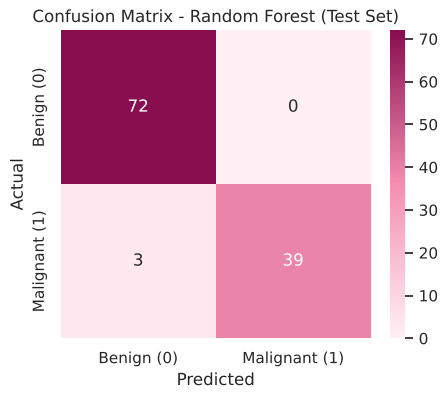

In [36]:
# Confusion matrix on the test set
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap=PINK_CMAP,
            xticklabels=['Benign (0)', 'Malignant (1)'],
            yticklabels=['Benign (0)', 'Malignant (1)'])
plt.title('Confusion Matrix - Random Forest (Test Set)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Reading the confusion matrix:**

| | Predicted Benign | Predicted Malignant |
|---|---|---|
| **Actual Benign** | 72 (correct) | 0 (false alarm) |
| **Actual Malignant** | 3 (missed cancer) | 39 (correct) |

1- All 72 benign patients were classified correctly, so there were 0 false alarms.

2- 39 malignant patients were found correctly.

3- 3 patients with cancer were predicted as benign. In real life, these patients might not get treatment in time, so this is the main error we want to reduce.

<a id="section-8-4" name="section-8-4"></a>

### 8.4 Classification Report

Print the classification report, which shows precision, recall and F1 for each class separately.

In [37]:
# Precision, recall and f1 for each class
print(classification_report(y_test, y_pred_test, target_names=['Benign', 'Malignant']))

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



1- The benign class has recall 1.00 (no benign patient was misclassified).

2- The malignant class has precision 1.00 but recall 0.93, so the model's errors are only in one direction: it sometimes predicts benign for a malignant tumor.

3- This happens because malignant cases are fewer (37%) and some of them look similar to benign ones (this overlap was visible in the scatter plot in the EDA).

<a id="section-8-5" name="section-8-5"></a>

### 8.5 Cross Validation vs Test Set

Compare the cross validation scores (from training) with the test scores to check for overfitting.

In [38]:
# Cross validation scores of rf_best on the training set
y_pred_cv = cross_val_predict(rf_best, X_train, y_train, cv=cv)

scores = pd.DataFrame({
    'Cross Validation (train)': [accuracy_score(y_train, y_pred_cv), precision_score(y_train, y_pred_cv),
                                 recall_score(y_train, y_pred_cv), f1_score(y_train, y_pred_cv)],
    'Test Set': [accuracy_score(y_test, y_pred_test), precision_score(y_test, y_pred_test),
                 recall_score(y_test, y_pred_test), f1_score(y_test, y_pred_test)]
}, index=['Accuracy', 'Precision', 'Recall', 'F1']).round(3)
scores

,Cross Validation (train),Test Set
Accuracy,0.963,0.974
Precision,0.942,1.000
Recall,0.959,0.929
F1,0.950,0.963


1- The test scores are very close to the cross validation scores (accuracy 96.3% vs 97.4%), so the model is **not overfitting** and works well on new data.

2- Test recall (0.929) is a little lower than CV recall (0.959), and precision is higher (1.0 vs 0.942).

3- The test set has only 42 malignant patients, so missing one cancer changes recall by about 2.4%. This means small differences between CV and test are normal, and the cross validation scores (455 patients) are the more stable estimate.

<a id="section-8-6" name="section-8-6"></a>

### 8.6 Feature Importance

Plot the top 10 features that helped the random forest the most in its splits.

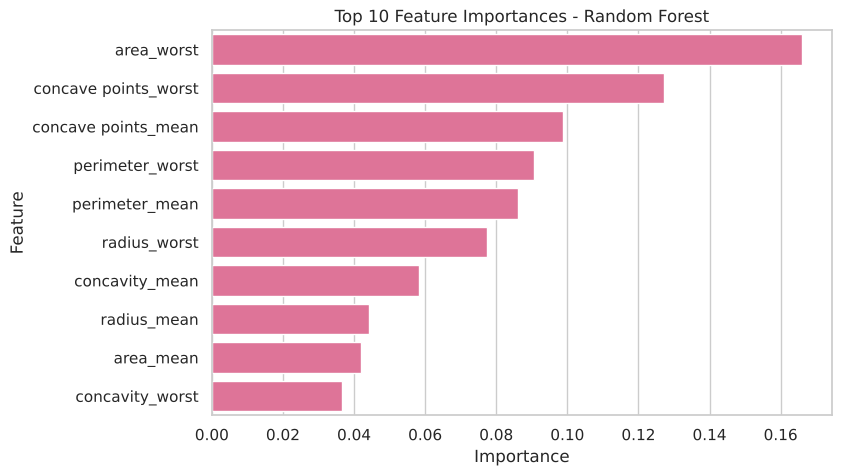

area_worst              0.166
concave points_worst    0.127
concave points_mean     0.099
perimeter_worst         0.091
perimeter_mean          0.086
radius_worst            0.077
concavity_mean          0.058
radius_mean             0.044
area_mean               0.042
concavity_worst         0.036
dtype: float64


In [39]:
# Top 10 most important features
importance = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.head(10).values, y=importance.head(10).index, color=PINKS[1])
plt.title('Top 10 Feature Importances - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

print(importance.head(10).round(3))

1- The most important features are `area_worst`, `concave points_worst` and `concave points_mean`.

2- Most of the top features are about the **size** (area, perimeter, radius) and **shape** (concave points, concavity) of the cell nucleus.

3- This matches the EDA: malignant tumors had a larger mean radius, and radius, perimeter and area were strongly correlated. Random forest uses these size features a lot to separate the classes.

4- Texture, smoothness and symmetry are not in the top 10, so they help less in this dataset.

<a id="section-9" name="section-9"></a>

## 9. Model Comparison (Bonus)

Compare the random forest with 4 other classification models:

* Decision Tree: a single tree (random forest is many trees, so this shows whether the forest helps)
* Logistic Regression
* KNN (K=5)
* SVM (RBF kernel)

Logistic regression, KNN and SVM depend on distances / feature size, so they need scaling . `StandardScaler` is placed inside a pipeline, so the scaler is fitted only on the training data in each fold.

All models use the same cross validation on the training set and the same test set.

Train every model with the same cross validation and test set.

In [40]:
# The models we want to compare
models = {
    'Random Forest (tuned)': rf_best,
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'KNN (K=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42))
}

results = []
for name, model in models.items():
    # Cross validation on the training set
    y_cv = cross_val_predict(clone(model), X_train, y_train, cv=cv)
    # Train on the full training set and test on the test set
    m = clone(model).fit(X_train, y_train)
    y_te = m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_te).ravel()
    results.append({
        'Model': name,
        'CV Recall': recall_score(y_train, y_cv),
        'CV F1': f1_score(y_train, y_cv),
        'Test Accuracy': accuracy_score(y_test, y_te),
        'Test Precision': precision_score(y_test, y_te),
        'Test Recall': recall_score(y_test, y_te),
        'Test F1': f1_score(y_test, y_te),
        'Missed Cancers (FN)': fn,
        'False Alarms (FP)': fp
    })

results = pd.DataFrame(results).set_index('Model').round(3)
results

,CV Recall,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Missed Cancers (FN),False Alarms (FP)
Model,,,,,,,,
Random Forest (tuned),0.959,0.950,0.974,1.000,0.929,0.963,3,0
Decision Tree,0.894,0.897,0.930,0.905,0.905,0.905,4,4
Logistic Regression,0.953,0.964,0.965,0.975,0.929,0.951,3,1
KNN (K=5),0.918,0.951,0.956,0.974,0.905,0.938,4,1
SVM (RBF),0.947,0.961,0.974,1.000,0.929,0.963,3,0


Plot a bar chart to compare the recall and F1 of the models.

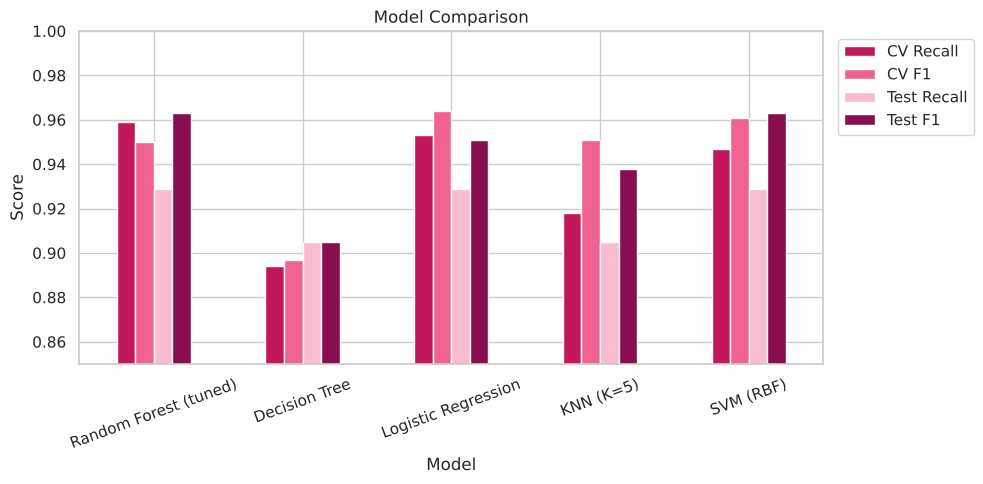

In [41]:
# Compare recall and f1 of the models
results[['CV Recall', 'CV F1', 'Test Recall', 'Test F1']].plot(kind='bar', figsize=(10, 5), color=PINKS)
plt.title('Model Comparison')
plt.ylabel('Score')
plt.ylim(0.85, 1.0)
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

1- Random Forest and SVM got the best test results (accuracy 97.4%, F1 0.963, 0 false alarms, 3 missed cancers).

2- Random forest has the highest CV recall (0.959), which is our most important metric. This is because it was tuned for recall and uses `class_weight='balanced'`.

3- The single Decision Tree is the weakest model (test accuracy 93%, 4 missed cancers and 4 false alarms). Random forest is much better because it combines many trees and takes the majority vote, which reduces overfitting.

4- Logistic regression and SVM are also very strong. This means the classes in this dataset are quite easy to separate, so simple models also work well.

5- KNN missed 4 cancers on the test set and has the lowest CV recall after the decision tree.

6- All the good models missed about 3 cancers, so these are probably hard cases that look similar to benign tumors.

<a id="section-10" name="section-10"></a>

## 10. Conclusion

In this project, we used a Random Forest Classifier to classify breast tumors as benign or malignant using the Breast Cancer Wisconsin dataset (569 patients, 30 features).

**What we did:**

1- Explored the data: no missing values (except the empty `Unnamed: 32` column), a moderate class imbalance (63% benign, 37% malignant), and a strong correlation between size features.

2- Prepared the data: removed `id` and `Unnamed: 32`, encoded the target (M = 1, B = 0), kept the outliers because they are real cancer cases, and did not scale because random forest does not need it.

3- Trained a random forest, handled class imbalance with `class_weight='balanced'` and tuned the hyperparameters to get the best recall.

4- Evaluated the final model on the test set and compared it with 4 other models.

**Final results on the test set:**

| Metric | Score |
|---|---|
| Accuracy | 97.4% |
| Precision | 1.000 |
| Recall | 0.929 |
| F1 Score | 0.963 |

**Key insights:**

1- The model is accurate and not overfitting (cross validation and test scores are close).

2- The size and shape of the cell nucleus (area, perimeter, concave points) are the most important features for the diagnosis.

3- The main error is missed cancers (3 out of 42), not false alarms (0). In medical diagnosis, recall is the most important metric, so we chose the model with the best recall.

4- Tuning improved recall in cross validation (missed cancers 10 → 7), while on the small test set the baseline and the tuned model gave the same result.

5- Random forest is much better than a single decision tree and performs as well as the best models we tried (SVM and logistic regression).

**Limitations:**

- The dataset is small , so one mistake changes the scores a lot.
- The model still misses some cancers, so it should be used to help doctors, not to replace them.

**Future work:**

- Try a bigger dataset with more patients.
- Try other models like Gradient Boosting / XGBoost.
- Adjust the decision threshold together with doctors to find the best balance between missed cancers and false alarms.